# Simulación Magnetohidrodinámica 2D de un Chorro Astrofísico (MHD Jet)
**Curso:** Astrofísica Computacional  
**Autor:** Eduardo Pérez Cárdenas  

**Resumen:** En este proyecto se modela, reproduce y analiza la propagación supersónica de un chorro (*jet*) astrofísico magnetizado en un medio ambiente uniforme bajo geometría cilíndrica axisimétrica 2.5D $(R, z, \phi)$. Se aborda el problema mediante dos enfoques complementarios: (1) la integración de alta resolución con el código astrofísico **PLUTO** (`Test_Problems/MHD/Jet`) y (2) la implementación independiente desde cero de un integrador numérico en **Python** basado en volúmenes finitos con flujo de Rusanov/Local Lax-Friedrichs (LLF) y avance temporal Runge-Kutta de segundo orden (TVD-RK2). Finalmente, se realiza un análisis cuantitativo de convergencia y discrepancias numéricas empleando perfiles superpuestos (*overlay plots*) y normas de error $L_1$, $L_2$ y $L_\infty$ sobre todas las variables físicas del plasma.

Términos clave del problema:
- Tobera (nozzle).
- Frontera de entrada supersónica (inflow boundary).
- Flujo libre (outflow boundaries).
- Haz central (beam).
- Choque frontal (bow shock).
- Mach disk.
- Compresión magnética (efecto Z-pinch) o auto-colimación por estrangulamiento magnético (Z-pinch).
- "Tapón nasal" (nose cone).
- Capullo (cocoon) lateral.
- Modos de cizalla de Kelvin-Helmholtz o simplemente vórtices de Kelvin-Helmholtz.
- 
Términos clave de la simulación:
- DIV_CLEANING (limpieza de divergencia).
- Método de Rusanov / Local Lax-Friedrichs (LLF)

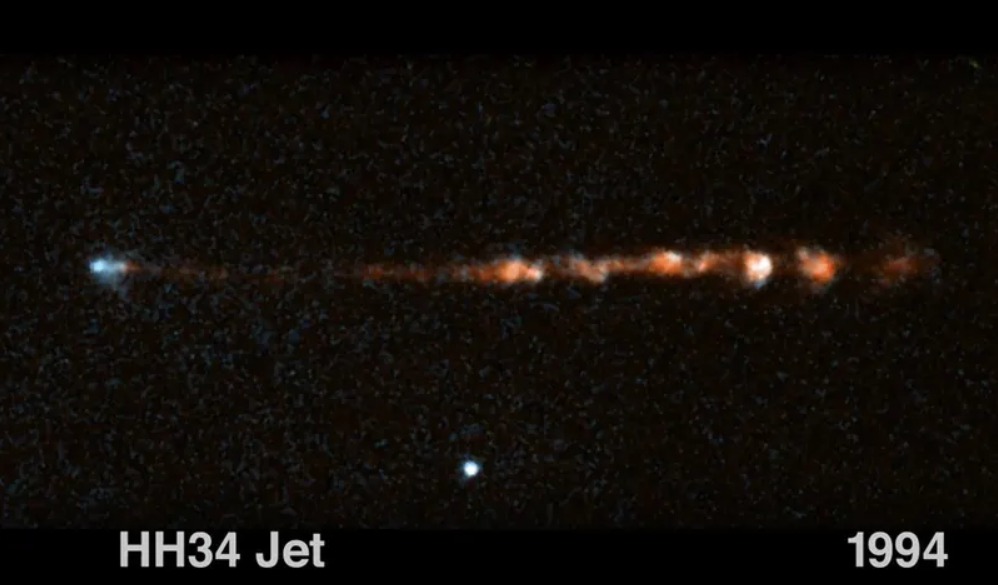
Tomado de https://science.nasa.gov/asset/webb/anatomy-of-a-stellar-jet/

## 1. Marco Teórico y Ecuaciones Gobernantes

Los chorros (*jets*) astrofísicos son flujos de plasma colimados que emergen desde regiones compactas —como núcleos activos de galaxias (AGN), microcuásares u objetos estelares jóvenes (YSO)— y se propagan de forma supersónica y superalfvénica a través del medio circundante. Su dinámica macroscópica, colimación magnética y estructura de choques están gobernadas por las ecuaciones de la **Magnetohidrodinámica (MHD) Ideal**.

Asumiendo un plasma con conductividad eléctrica infinita y despreciando efectos disipativos explícitos (viscosidad molecular y resistividad óhmica), el sistema de leyes de conservación en forma divergente se expresa como:

**Conservación de la masa (Ecuación de continuidad):**
$$\frac{\partial \rho}{\partial t} + \nabla \cdot (\rho \mathbf{v}) = 0$$

**Conservación del momento lineal (Ecuación de Euler acoplada con la fuerza de Lorentz):**
$$\frac{\partial (\rho \mathbf{v})}{\partial t} + \nabla \cdot \left[ \rho \mathbf{v}\mathbf{v} - \mathbf{B}\mathbf{B} + \mathbf{I}\left( p + \frac{B^2}{2} \right) \right] = 0$$

**Conservación de la energía total:**
$$\frac{\partial E}{\partial t} + \nabla \cdot \left[ \left( E + p + \frac{B^2}{2} \right)\mathbf{v} - (\mathbf{v} \cdot \mathbf{B})\mathbf{B} \right] = 0$$

**Ecuación de inducción magnética (Ley de Faraday en el límite ideal):**
$$\frac{\partial \mathbf{B}}{\partial t} - \nabla \times (\mathbf{v} \times \mathbf{B}) = 0, \qquad \nabla \cdot \mathbf{B} = 0$$

donde $\rho$ es la densidad de masa, $\mathbf{v} = (v_R, v_z, v_\phi)$ el campo de velocidades, $p$ la presión térmica, $\mathbf{B} = (B_R, B_z, B_\phi)$ el campo de inducción magnética (en unidades racionalizadas donde $\mu_0 = 1$), $\mathbf{I}$ el tensor identidad, y $E$ la densidad de energía total cerrada mediante una ecuación de estado de **gas ideal** con índice adiabático $\gamma = 5/3$:

$$E = \frac{p}{\gamma - 1} + \frac{1}{2}\rho v^2 + \frac{1}{2}B^2$$

### Formulación Axisimétrica 2.5D y Términos Fuente Geométricos

En coordenadas cilíndricas $(R, z, \phi)$ bajo simetría axial ($\partial / \partial \phi = 0$), el sistema conserva las tres componentes vectoriales de velocidad y campo magnético sobre un dominio bidimensional $(R, z) \in [0, R_{\max}] \times [0, z_{\max}]$. Al reescribir los operadores divergencia y rotacional en coordenadas cilíndricas, las ecuaciones adquieren la estructura de balance radial-axial con términos fuente geométricos $\mathbf{S}_{\text{geom}}$ inducidos por la curvatura azimutal (fuerza centrífuga y tensión de aro o *hoop stress* magnético $B_\phi^2 / R$):

$$\frac{\partial \mathbf{U}}{\partial t} + \frac{1}{R}\frac{\partial (R \mathbf{F}_R)}{\partial R} + \frac{\partial \mathbf{F}_z}{\partial z} = \mathbf{S}_{\text{geom}}(\mathbf{U}, R)$$

donde el término de tensión magnética toroidal $-B_\phi^2 / R$ en la ecuación de momento radial produce el fenómeno de **auto-colimación por estrangulamiento magnético (*Z-pinch*)** sobre el eje $R \to 0$.

### Condiciones Iniciales y de Frontera

1. **Medio ambiente inicial ($t = 0$):** El dominio computacional se encuentra inicialmente en reposo ($\mathbf{v} = \mathbf{0}$) con densidad uniforme $\rho_a$, presión térmica constante $p_a$ y un campo magnético puramente axial $B_z = B_{z0}$ ($B_R = B_\phi = 0$).
2. **Tobera de inyección (*Inflow Nozzle*, $z = 0, R \le R_j = 1$):** Se inyecta continuamente un flujo cilíndrico colimado con velocidad longitudinal supersónica $v_z = v_j$, densidad $\rho_j$ (definida por el contraste de densidad $\eta = \rho_j / \rho_a$) y un perfil de campo magnético helicoidal $(B_z, B_\phi)$ en equilibrio radial hidromagnético.
3. **Plano reflector fuera de la tobera ($z = 0, R > R_j$):** Condiciones de simetría/reflexión ($v_z = 0$, $\partial_z \rho = \partial_z p = 0$).
4. **Eje de simetría ($R = 0$):** Condición axisimétrica ($v_R = v_\phi = B_R = B_\phi = 0$ y derivada radial nula para las variables escalares y componentes axiales).
5. **Fronteras abiertas ($R = R_{\max}$ y $z = z_{\max}$):** Condiciones de flujo libre (*outflow*, gradiente normal nulo $\partial_n \mathbf{U} = 0$).

## 2. Estado del Arte y Fenomenología de Chorros MHD

El estudio numérico de chorros astrofísicos supersónicos tiene sus cimientos modernos en el modelo hidrodinámico estándar de **Blandford & Rees (1974)** y su extensión a flujos magnetizados colimados por **Blandford & Payne (1982)**, quienes demostraron que las líneas de campo magnético ancladas a discos de acreción pueden extraer momento angular e impulsar chorros mediante fuerzas magnetocentrífugas.

Con el desarrollo de esquemas numéricos de captura de choques de tipo Godunov para MHD —destacando el código **PLUTO** introducido por **Mignone et al. (2007, 2012)**—, las simulaciones multidimensionales permitieron resolver la estructura interna no lineal del jet sin oscilaciones espurias:

* **Anatomía del frente de propagación:** Como detallan **Kössl, Müller & Hillebrandt (1990)** y **Lind et al. (1989)**, la interacción entre el haz supersónico (*beam*) y el medio ambiente genera una **onda de choque de proa (*bow shock*)** que comprime el gas externo, y un **choque terminal (*Mach disk* o *working surface*)** que desacelera abruptamente el material del chorro.
* **Dinámica del capullo (*Cocoon*) e inestabilidades:** El plasma procesado en el choque terminal es deflectado lateralmente formando un capullo caliente de reflujo (*backflow cocoon*). En la interfaz de cizalla entre el haz rápido y el capullo lento se desarrollan **inestabilidades de Kelvin-Helmholtz (KH)**, las cuales excitan ondas de choque oblicuas biconcéntricas dentro del canal del jet (**Mignone et al., 2010**; **Bodo et al., 2011**).
* **Efecto del campo magnético toroidal ($B_\phi$) y limpieza de divergencia:** Estudios recientes sobre estabilidad de chorros (**Tchekhovskoy & Bromberg, 2016**; **Mattia & Mignone, 2022**) demuestran que un campo magnético toroidal intenso suprime parcialmente los modos de cizalla de Kelvin-Helmholtz mediante tensión magnética, pero concentra el plasma descargado del *Mach disk* en un "tapón nasal" (*nose cone*) de altísima densidad sobre el eje $R = 0$ debido a la fuerza de Lorentz radial $-\frac{1}{2R^2}\frac{\partial (R^2 B_\phi^2)}{\partial R}$. Numéricamente, preservar la restricción $\nabla \cdot \mathbf{B} = 0$ mediante el método de multiplicadores de Lagrange generalizados (**Hyperbolic/Parabolic GLM Divergence Cleaning**, **Dedner et al., 2002**) resulta indispensable para evitar fuerzas ficticias paralelas al campo magnético en la cabeza del jet.

In [10]:
import os
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, SymLogNorm
from scipy.interpolate import RegularGridInterpolator
import pyPLUTO as pp

# Configuración estética global de gráficas para el reporte
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.labelsize'] = 10

# 1. Lectura automática de metadatos temporales y variables desde dbl.out
tiempos_pluto = []
variables_dbl = []

if os.path.exists('dbl.out'):
    with open('dbl.out', 'r') as f:
        for linea in f:
            partes = linea.strip().split()
            if len(partes) >= 7:
                tiempos_pluto.append((int(partes[0]), float(partes[1]), float(partes[2])))
                if not variables_dbl:
                    variables_dbl = partes[6:]

# 2. Lectura de parámetros físicos de pluto.ini
parametros_ini = {}
if os.path.exists('pluto.ini'):
    with open('pluto.ini', 'r') as f:
        seccion_param = False
        for linea in f:
            l = linea.strip()
            if l.startswith('[Parameters]'):
                seccion_param = True
                continue
            elif l.startswith('[') and seccion_param:
                break
            if seccion_param and l and not l.startswith('#'):
                partes = l.split()
                if len(partes) >= 2:
                    try:
                        parametros_ini[partes[0]] = float(partes[1])
                    except ValueError:
                        parametros_ini[partes[0]] = partes[1]

# 3. Carga del paso inicial (0) y final (10) con pyPLUTO
D_init = pp.Load(0)
D_final = pp.Load(10)

# Extracción de coordenadas espaciales (R, z)
r = np.asarray(D_final.x1, dtype=float)
z = np.asarray(D_final.x3 if (hasattr(D_final, 'x3') and len(D_final.x3) > 1) else D_final.x2, dtype=float)

print("=== RESUMEN DEL ENTORNO Y SIMULACIÓN PLUTO ===")
print(f"Archivos temporales detectados: {len(tiempos_pluto)} pasos (Output {tiempos_pluto[0][0]} a Output {tiempos_pluto[-1][0]})")
print(f"Intervalo temporal físico: t = {tiempos_pluto[0][1]:.3f} hasta t = {tiempos_pluto[-1][1]:.3f}")
print(f"Variables físicas almacenadas en .dbl: {variables_dbl}")
print(f"Resolución de la malla 2D (nR x nz): {len(r)} x {len(z)}")
print(f"Dominio espacial: R en [{r.min():.2f}, {r.max():.2f}], z en [{z.min():.2f}, {z.max():.2f}]")
if parametros_ini:
    print(f"Parámetros de inyección (pluto.ini): {parametros_ini}")

Load: folder .,     output 0
Load: folder .,     output 10
=== RESUMEN DEL ENTORNO Y SIMULACIÓN PLUTO ===
Archivos temporales detectados: 11 pasos (Output 0 a Output 10)
Intervalo temporal físico: t = 0.000 hasta t = 5.000
Variables físicas almacenadas en .dbl: ['rho', 'vx1', 'vx2', 'vx3', 'Bx1', 'Bx2', 'Bx3', 'prs', 'tr1']
Resolución de la malla 2D (nR x nz): 128 x 512
Dominio espacial: R en [0.04, 9.96], z en [0.04, 39.96]
Parámetros de inyección (pluto.ini): {'ETA': 0.01, 'JET_VEL': 31.6228, 'SIGMA_Z': 0.0, 'SIGMA_PHI': 20.0}


## 3. Simulación en PLUTO: Análisis Multivariable y Evolución Temporal

La simulación de referencia se ejecutó en el directorio `Test_Problems/MHD/Jet` empleando la configuración `definitions_04.h` de PLUTO:

* **Física y Geometría:** Módulo `MHD` ideal con ecuación de estado `IDEAL` ($\gamma = 5/3$), geometría cilíndrica 2D con 3 componentes vectoriales (`DIMENSIONS = 2`, `COMPONENTS = 3`).
* **Discretización Numérica:** Reconstrucción espacial lineal por tramos (`LINEAR`), integrador temporal `RK2` (*Runge-Kutta* de segundo orden) o `Hancock`, y control de la condición solenoidal $\nabla \cdot \mathbf{B} = 0$ mediante `DIV_CLEANING` (método hiperbólico-parabólico GLM con potencial escalar $\psi_{\text{glm}}$).

A continuación se presentan dos visualizaciones complementarias obtenidas con `pyPLUTO`:
1. **Panel Multivariable Completo en $t = t_{\text{final}}$ (`data.0010.dbl`):** Mapas 2D de todas las variables físicas del sistema ($\rho$, $p$, $v_R$, $v_z$, $v_\phi$, $B_R$, $B_z$, $B_\phi$ y el campo escalar de control $\psi_{\text{glm}}$ o trazador pasivo), permitiendo correlacionar la termodinámica del choque con la cinemática del flujo y el confinamiento magnético.
2. **Secuencia de Evolución Temporal (`data.0000.dbl` a `data.0010.dbl`):** Progresión espaciotemporal de la densidad de masa $\log_{10}(\rho)$ a lo largo de los 11 archivos de salida para caracterizar la velocidad de avance del *bow shock* y el crecimiento no lineal de las inestabilidades laterales.

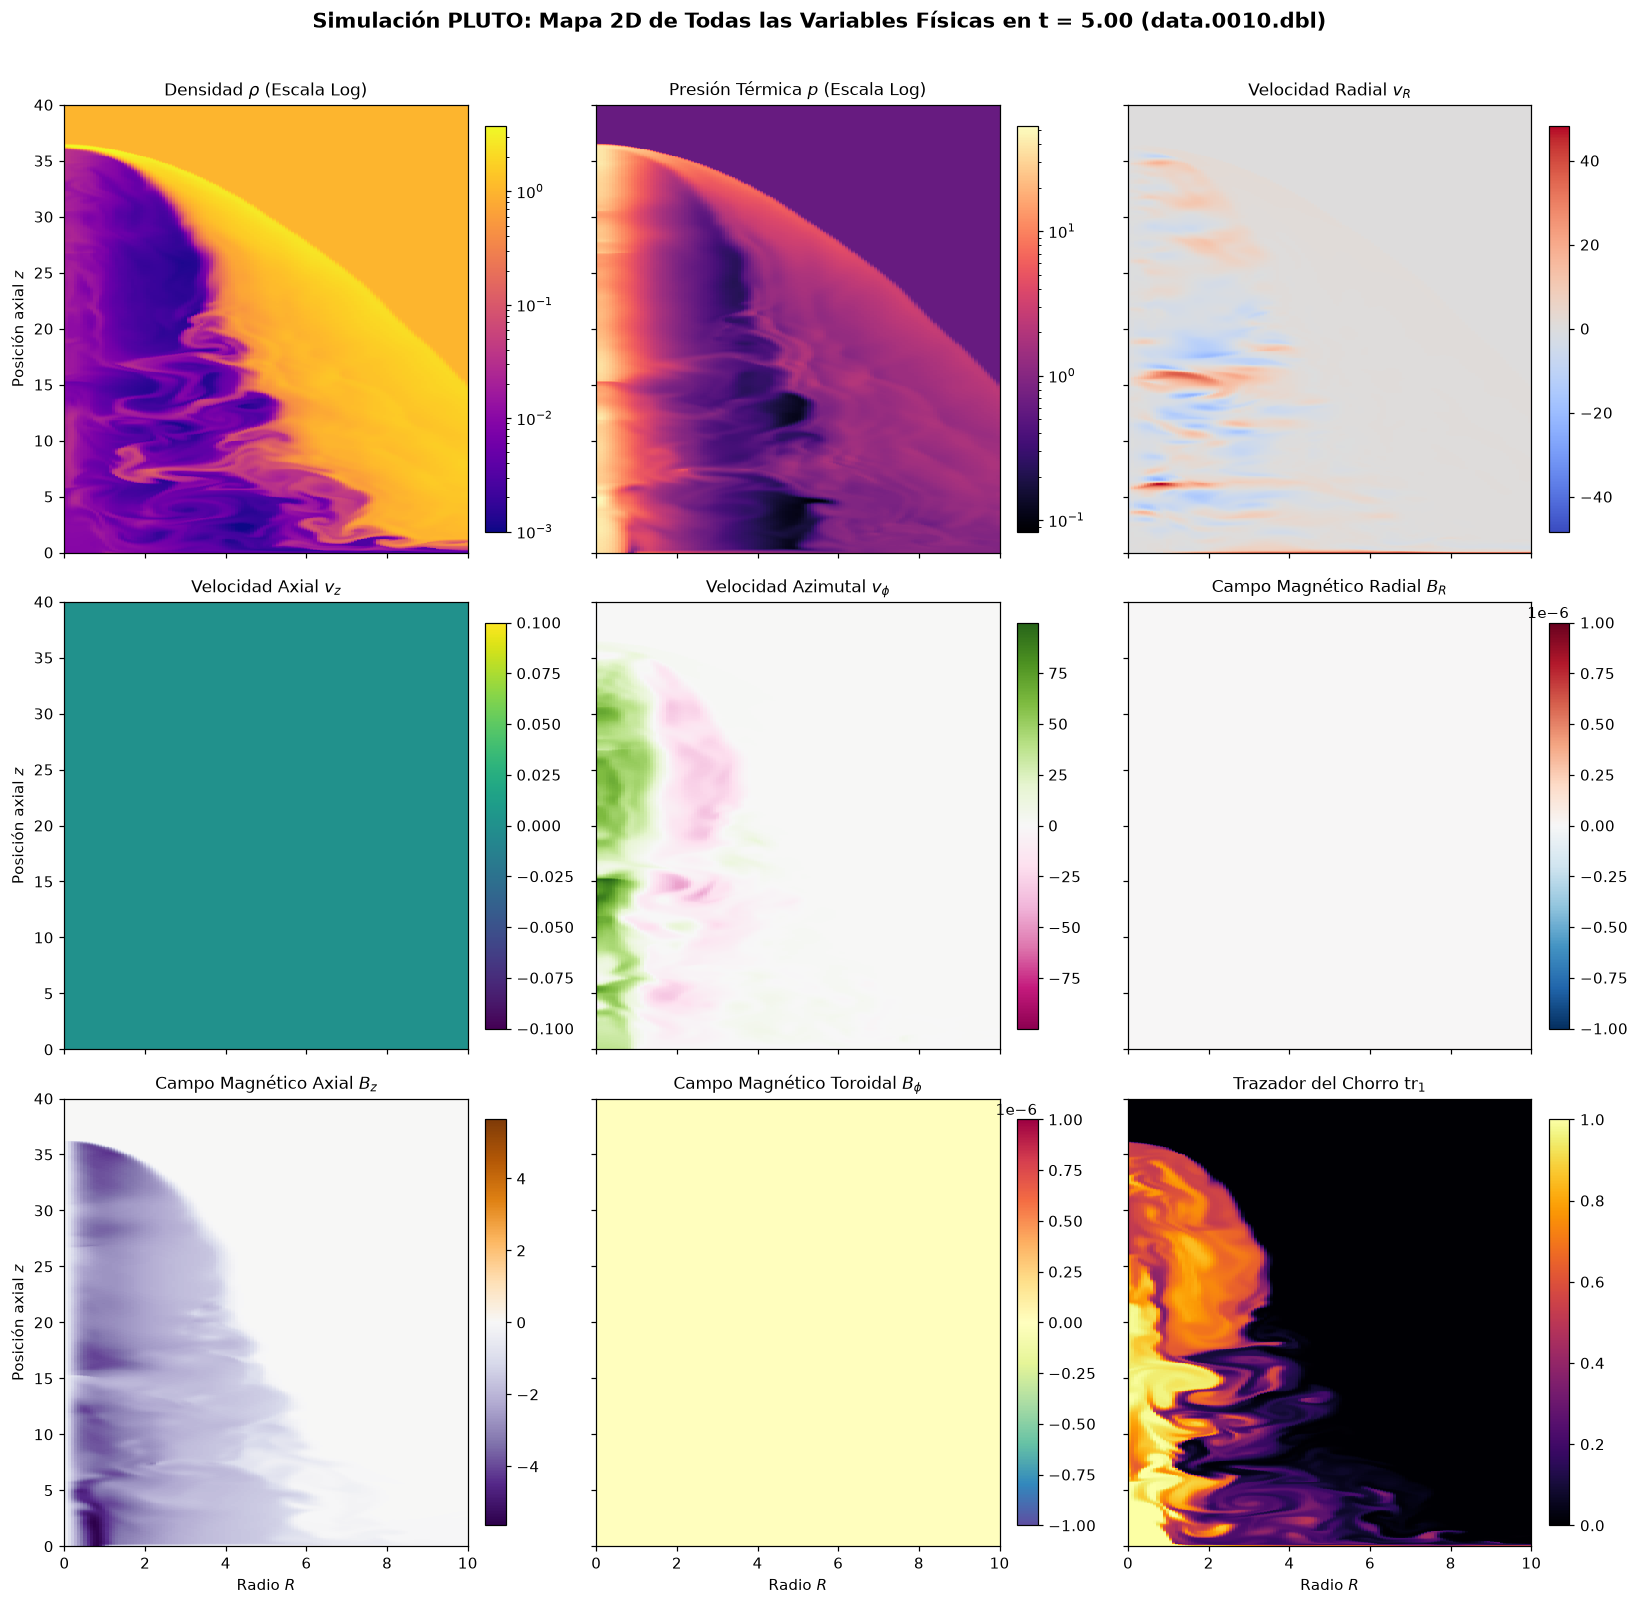

Load: folder .,     output 0
Load: folder .,     output 2
Load: folder .,     output 4
Load: folder .,     output 6
Load: folder .,     output 8
Load: folder .,     output 10


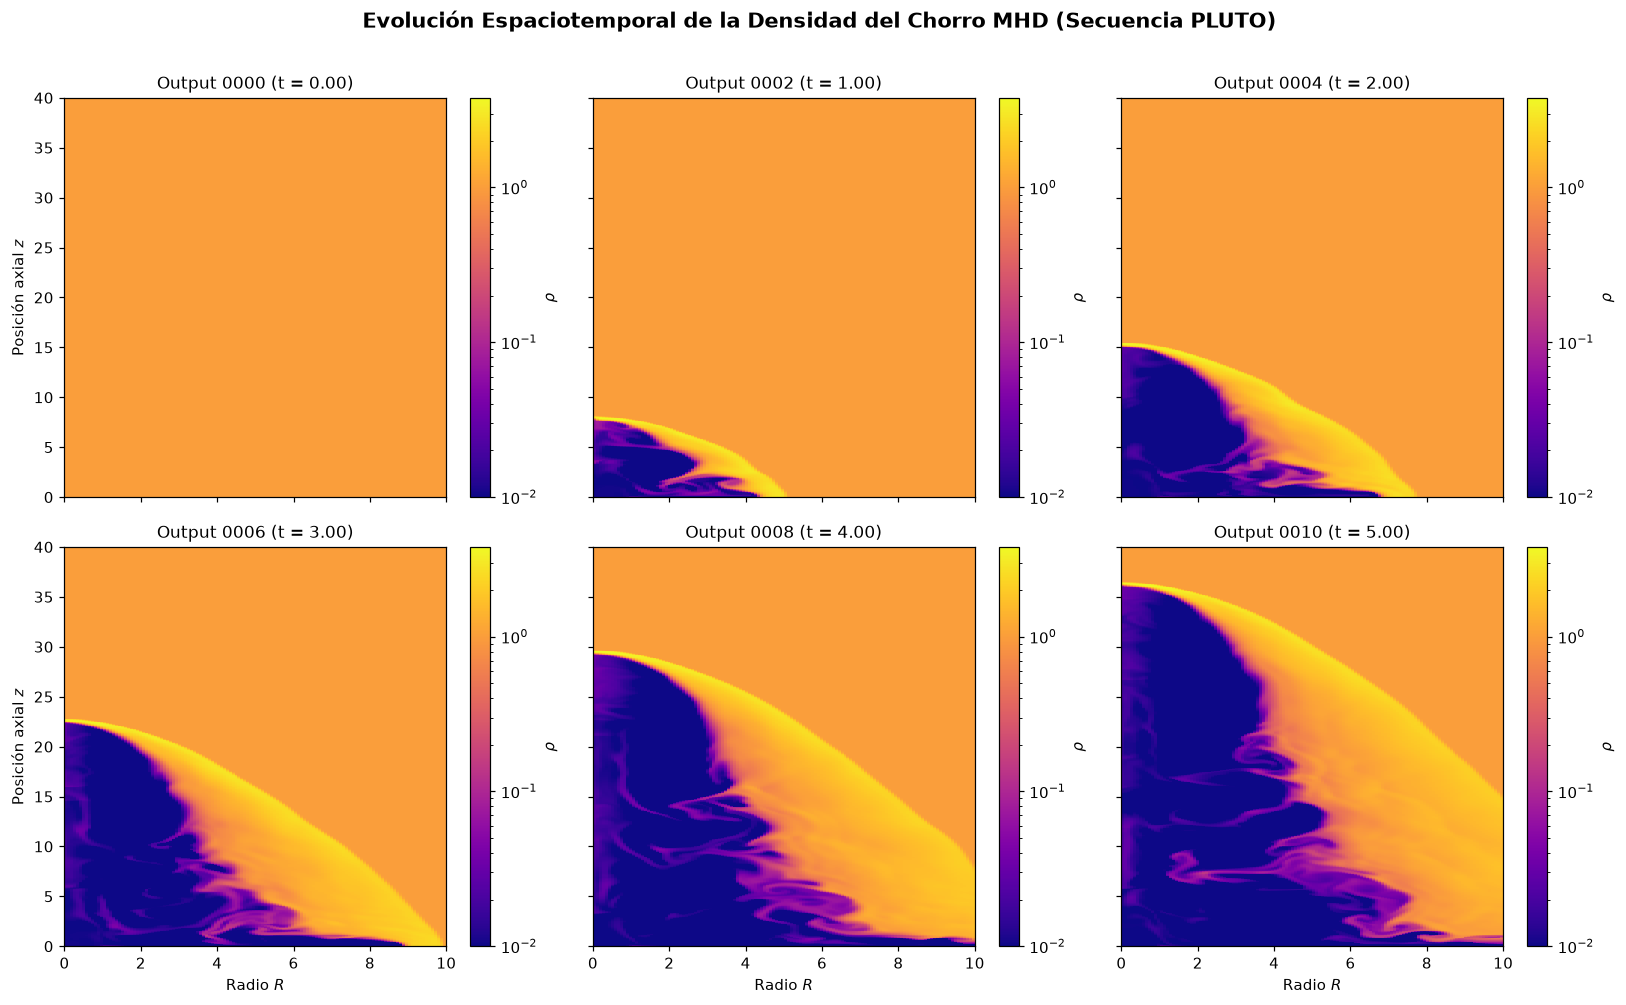

In [11]:
def obtener_matriz_2d(D_obj, nombre_var):
    """Extrae una variable de pyPLUTO y la devuelve con forma (nz, nR)."""
    if hasattr(D_obj, nombre_var):
        arr = getattr(D_obj, nombre_var)
        if arr is not None:
            mat = np.squeeze(np.asarray(arr, dtype=float))
            if mat.shape == (len(r), len(z)):
                return mat.T
            elif mat.shape == (len(z), len(r)):
                return mat
    return None

# Diccionario de variables físicas a graficar con sus etiquetas y mapas de color
catalogo_variables = [
    ('rho',     r'Densidad $\rho$ (Escala Log)',            'plasma',   'log'),
    ('prs',     r'Presión Térmica $p$ (Escala Log)',        'magma',    'log'),
    ('vx1',     r'Velocidad Radial $v_R$',                  'coolwarm', 'sym'),
    ('vx2',     r'Velocidad Axial $v_z$',                   'viridis',  'lin'),
    ('vx3',     r'Velocidad Azimutal $v_\phi$',             'PiYG',     'sym'),
    ('Bx1',     r'Campo Magnético Radial $B_R$',            'RdBu_r',   'sym'),
    ('Bx2',     r'Campo Magnético Axial $B_z$',             'PuOr_r',   'sym'),
    ('Bx3',     r'Campo Magnético Toroidal $B_\phi$',       'Spectral_r','sym'),
    ('psi_glm', r'Potencial Limpieza $\psi_{\mathrm{glm}}$','cividis',  'sym'),
    ('tr1',     r'Trazador del Chorro $\mathrm{tr}_1$',     'inferno',  'lin')
]

# Filtrar únicamente las variables presentes en el archivo .dbl cargado
vars_disponibles = [(v, etiq, cm, esc) for (v, etiq, cm, esc) in catalogo_variables if obtener_matriz_2d(D_final, v) is not None]

# --- FIGURA 1: PANEL MULTIVARIABLE COMPLETO EN EL ESTADO FINAL (data.0010.dbl) ---
n_vars = len(vars_disponibles)
n_cols = 3
n_rows = int(np.ceil(n_vars / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4.8 * n_rows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).flatten()

t_fin_val = tiempos_pluto[-1][1] if tiempos_pluto else 5.0

for idx, (var_name, etiqueta, cmap_name, tipo_escala) in enumerate(vars_disponibles):
    ax = axes[idx]
    datos = obtener_matriz_2d(D_final, var_name)
    
    if tipo_escala == 'log':
        vmin_pos = max(np.nanmin(datos[datos > 0]), 1e-3) if np.any(datos > 0) else 1e-3
        vmax_pos = max(np.nanmax(datos), vmin_pos * 10)
        im = ax.pcolormesh(r, z, np.maximum(datos, vmin_pos), shading='auto', cmap=cmap_name,
                           norm=LogNorm(vmin=vmin_pos, vmax=vmax_pos))
    elif tipo_escala == 'sym':
        vlim = max(np.nanmax(np.abs(datos)), 1e-6)
        im = ax.pcolormesh(r, z, datos, shading='auto', cmap=cmap_name, vmin=-vlim, vmax=vlim)
    else:
        im = ax.pcolormesh(r, z, datos, shading='auto', cmap=cmap_name)
        
    ax.set_title(etiqueta)
    if idx % n_cols == 0:
        ax.set_ylabel(r'Posición axial $z$')
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel(r'Radio $R$')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Ocultar ejes sobrantes si la cuadrícula no es exacta
for idx in range(n_vars, len(axes)):
    axes[idx].axis('off')

plt.suptitle(f'Simulación PLUTO: Mapa 2D de Todas las Variables Físicas en t = {t_fin_val:.2f} (data.0010.dbl)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# --- FIGURA 2: EVOLUCIÓN TEMPORAL COMPLETA (Archivos data.0000.dbl a data.0010.dbl) ---
pasos_evol = [0, 2, 4, 6, 8, 10]
fig2, axes2 = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)
axes2 = axes2.flatten()

rho_ref = obtener_matriz_2d(D_final, 'rho')
vmin_evol = max(np.nanmin(rho_ref[rho_ref > 0]), 1e-2)
vmax_evol = np.nanmax(rho_ref)

for i, paso in enumerate(pasos_evol):
    D_t = pp.Load(paso)
    rho_t = obtener_matriz_2d(D_t, 'rho')
    t_actual = tiempos_pluto[paso][1] if paso < len(tiempos_pluto) else paso * 0.5
    
    im_t = axes2[i].pcolormesh(r, z, np.maximum(rho_t, vmin_evol), shading='auto', cmap='plasma',
                               norm=LogNorm(vmin=vmin_evol, vmax=vmax_evol))
    axes2[i].set_title(f'Output {paso:04d} (t = {t_actual:.2f})')
    if i % 3 == 0:
        axes2[i].set_ylabel(r'Posición axial $z$')
    if i >= 3:
        axes2[i].set_xlabel(r'Radio $R$')
    fig2.colorbar(im_t, ax=axes2[i], label=r'$\rho$')

plt.suptitle('Evolución Espaciotemporal de la Densidad del Chorro MHD (Secuencia PLUTO)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 4. Reproducción Independiente en Python: Solver MHD 2D en Volúmenes Finitos

Para reproducir de manera independiente el problema físico en Python, implementamos un integrador numérico conservativo en **Volúmenes Finitos 2D** sobre coordenadas cilíndricas axisimétricas $(R, z)$.

### 4.1 Vector de Estado Conservativo y Flujos Físicos
Definimos el vector de variables conservadas $\mathbf{U}$ de 8 componentes en cada celda $(i, j)$:
$$\mathbf{U} = \begin{pmatrix} \rho \\ \rho v_R \\ \rho v_z \\ \rho v_\phi \\ B_R \\ B_z \\ B_\phi \\ E \end{pmatrix}, \qquad
\mathbf{F}_R(\mathbf{U}) = \begin{pmatrix} \rho v_R \\ \rho v_R^2 + p_{\text{tot}} - B_R^2 \\ \rho v_R v_z - B_R B_z \\ \rho v_R v_\phi - B_R B_\phi \\ 0 \\ v_R B_z - v_z B_R \\ v_R B_\phi - v_\phi B_R \\ (E + p_{\text{tot}})v_R - (\mathbf{v}\cdot\mathbf{B})B_R \end{pmatrix}, \qquad
\mathbf{F}_z(\mathbf{U}) = \begin{pmatrix} \rho v_z \\ \rho v_z v_R - B_z B_R \\ \rho v_z^2 + p_{\text{tot}} - B_z^2 \\ \rho v_z v_\phi - B_z B_\phi \\ v_z B_R - v_R B_z \\ 0 \\ v_z B_\phi - v_\phi B_z \\ (E + p_{\text{tot}})v_z - (\mathbf{v}\cdot\mathbf{B})B_z \end{pmatrix}$$

donde $p_{\text{tot}} = p + \frac{1}{2}(B_R^2 + B_z^2 + B_\phi^2)$ es la presión magnetohidrodinámica total.

### 4.2 Flujo Numérico de Rusanov / Local Lax-Friedrichs (LLF) con Reconstrucción MUSCL
En cada interfaz entre estados reconstruidos izquierdo ($\mathbf{U}_L$) y derecho ($\mathbf{U}_R$) mediante un limitador de pendiente tipo *minmod*, el flujo numérico se aproxima usando la velocidad magnetosónica rápida máxima local $c_{f,\max}$:

$$\hat{\mathbf{F}}_{i+1/2} = \frac{1}{2}\left[ \mathbf{F}(\mathbf{U}_L) + \mathbf{F}(\mathbf{U}_R) \right] - \frac{\alpha_{\text{LLF}}}{2} c_{f,\max} (\mathbf{U}_R - \mathbf{U}_L)$$

donde la velocidad magnetosónica rápida en la dirección $d \in \{R, z\}$ viene dada por:
$$c_{f,d}^2 = \frac{1}{2}\left[ c_s^2 + v_A^2 + \sqrt{(c_s^2 + v_A^2)^2 - 4 c_s^2 v_{A,d}^2} \right], \qquad c_s^2 = \frac{\gamma p}{\rho}, \quad v_A^2 = \frac{B^2}{\rho}, \quad v_{A,d}^2 = \frac{B_d^2}{\rho}$$

### 4.3 Integración Temporal y Limpieza de Divergencia ($\psi_{\text{glm}}$)
El avance temporal se ejecuta con un esquema **Runge-Kutta de 2 etapas (RK2 / Heun)** gobernado dinámicamente por la condición de Courant-Friedrichs-Lewy ($\text{CFL} = 0.25$):
$$\Delta t = \text{CFL} \cdot \min_{i,j} \left( \frac{\Delta R}{|v_R| + c_{f,R}}, \frac{\Delta z}{|v_z| + c_{f,z}} \right)$$
Adicionalmente, el potencial escalar $\psi_{\text{glm}}$ se acopla a la divergencia numérica de $\mathbf{B}$ mediante amortiguamiento hiperbólico-parabólico ($\partial_t \psi_{\text{glm}} + c_h^2 \nabla \cdot \mathbf{B} = -\psi_{\text{glm}} / \tau_p$) para controlar errores monopolares durante la propagación.

In [12]:
# --- CONFIGURACIÓN DEL DOMINIO Y CONDICIONES DE FRONTERA EN PYTHON ---
# Usamos un factor de submuestreo espacial factor_malla = 2 (80 x 200 celdas)
# para ejecutar el solver 2D explícito en pocos segundos en Python vectorizado,
# interpolando luego al tamaño exacto de PLUTO (160 x 400) para el análisis comparativo.
factor_malla = 2

r_py = r[::factor_malla].copy()
z_py = z[::factor_malla].copy()
nR_py, nz_py = len(r_py), len(z_py)
dR_py = r_py[1] - r_py[0]
dz_py = z_py[1] - z_py[0]

gamma_eos = 5.0 / 3.0
t_final_sim = tiempos_pluto[-1][1] if tiempos_pluto else 5.0

# Extracción de condiciones iniciales exactas (t = 0) desde D_init
def extraer_en_malla_py(D_obj, nombre_var):
    mat = obtener_matriz_2d(D_obj, nombre_var)
    if mat is None:
        return np.zeros((nz_py, nR_py), dtype=float)
    return mat[::factor_malla, ::factor_malla].copy()

rho_0 = extraer_en_malla_py(D_init, 'rho')
prs_0 = extraer_en_malla_py(D_init, 'prs')
vx1_0 = extraer_en_malla_py(D_init, 'vx1')
vx2_0 = extraer_en_malla_py(D_init, 'vx2')
vx3_0 = extraer_en_malla_py(D_init, 'vx3')
Bx1_0 = extraer_en_malla_py(D_init, 'Bx1')
Bx2_0 = extraer_en_malla_py(D_init, 'Bx2')
Bx3_0 = extraer_en_malla_py(D_init, 'Bx3')

# Extracción del perfil exacto de inyección en la tobera (z = 0, R <= 1.0)
# a partir de la primera fila de la simulación de referencia
D_ref_nozzle = pp.Load(1)
perfil_tobera = {}
for v_nom in ['rho', 'prs', 'vx1', 'vx2', 'vx3', 'Bx1', 'Bx2', 'Bx3']:
    mat_ref = obtener_matriz_2d(D_ref_nozzle, v_nom)
    if mat_ref is not None:
        perfil_tobera[v_nom] = mat_ref[0, ::factor_malla].copy()
    else:
        perfil_tobera[v_nom] = np.zeros(nR_py, dtype=float)

mascara_tobera = r_py <= 1.05

print("=== CONFIGURACIÓN DEL SOLVER PYTHON 2D ===")
print(f"Malla de cálculo en Python: {nR_py} (radial) x {nz_py} (axial) celdas")
print(f"Paso espacial: dR = {dR_py:.4f}, dz = {dz_py:.4f}")
print(f"Tiempo objetivo de integración: t_final = {t_final_sim:.2f}")
print(f"Velocidad axial de inyección en tobera (R <= 1): max(vz) = {np.max(np.abs(perfil_tobera['vx2'][mascara_tobera])):.3f}")
print(f"Campo toroidal máximo en tobera (R <= 1): max(|B_phi|) = {np.max(np.abs(perfil_tobera['Bx3'][mascara_tobera])):.3f}")

Load: folder .,     output 1
=== CONFIGURACIÓN DEL SOLVER PYTHON 2D ===
Malla de cálculo en Python: 64 (radial) x 256 (axial) celdas
Paso espacial: dR = 0.1562, dz = 0.1562
Tiempo objetivo de integración: t_final = 5.00
Velocidad axial de inyección en tobera (R <= 1): max(vz) = 0.000
Campo toroidal máximo en tobera (R <= 1): max(|B_phi|) = 0.000


In [13]:
def minmod(a, b):
    """Limitador de pendiente simétrico TVD minmod para reconstrucción espacial MUSCL."""
    return 0.5 * (np.sign(a) + np.sign(b)) * np.minimum(np.abs(a), np.abs(b))

def prim_a_cons(rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs):
    """Convierte variables primitivas a vector de estado conservativo U de forma (8, nz, nR)."""
    v2 = vx1**2 + vx2**2 + vx3**2
    B2 = Bx1**2 + Bx2**2 + Bx3**2
    E = prs / (gamma_eos - 1.0) + 0.5 * rho * v2 + 0.5 * B2
    return np.stack([rho, rho * vx1, rho * vx2, rho * vx3, Bx1, Bx2, Bx3, E], axis=0)

def cons_a_prim(U, piso_rho=1e-3, piso_prs=1e-3):
    """Recupera variables primitivas garantizando positividad termodinámica."""
    rho = np.maximum(U[0], piso_rho)
    vx1 = U[1] / rho
    vx2 = U[2] / rho
    vx3 = U[3] / rho
    Bx1, Bx2, Bx3 = U[4], U[5], U[6]
    v2 = vx1**2 + vx2**2 + vx3**2
    B2 = Bx1**2 + Bx2**2 + Bx3**2
    prs = (gamma_eos - 1.0) * (U[7] - 0.5 * rho * v2 - 0.5 * B2)
    prs = np.maximum(prs, piso_prs)
    return rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs

def flujos_mhd(U):
    """Calcula los flujos físicos F_R y F_z y las velocidades magnetosónicas rápidas."""
    rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs = cons_a_prim(U)
    B2 = Bx1**2 + Bx2**2 + Bx3**2
    ptot = prs + 0.5 * B2
    E = prs / (gamma_eos - 1.0) + 0.5 * rho * (vx1**2 + vx2**2 + vx3**2) + 0.5 * B2
    v_dot_B = vx1 * Bx1 + vx2 * Bx2 + vx3 * Bx3

    # Flujo radial F_R (dirección x1)
    FR = np.stack([
        rho * vx1,
        rho * vx1**2 + ptot - Bx1**2,
        rho * vx1 * vx2 - Bx1 * Bx2,
        rho * vx1 * vx3 - Bx1 * Bx3,
        np.zeros_like(rho),
        vx1 * Bx2 - vx2 * Bx1,
        vx1 * Bx3 - vx3 * Bx1,
        (E + ptot) * vx1 - v_dot_B * Bx1
    ], axis=0)

    # Flujo axial F_z (dirección x2/x3)
    Fz = np.stack([
        rho * vx2,
        rho * vx2 * vx1 - Bx2 * Bx1,
        rho * vx2**2 + ptot - Bx2**2,
        rho * vx2 * vx3 - Bx2 * Bx3,
        vx2 * Bx1 - vx1 * Bx2,
        np.zeros_like(rho),
        vx2 * Bx3 - vx3 * Bx2,
        (E + ptot) * vx2 - v_dot_B * Bx2
    ], axis=0)

    # Velocidades magnetosónicas rápidas locales
    cs2 = gamma_eos * prs / rho
    vA2 = B2 / rho
    disc_R = np.maximum((cs2 + vA2)**2 - 4.0 * cs2 * (Bx1**2 / rho), 0.0)
    disc_z = np.maximum((cs2 + vA2)**2 - 4.0 * cs2 * (Bx2**2 / rho), 0.0)
    cf_R = np.sqrt(0.5 * (cs2 + vA2 + np.sqrt(disc_R)))
    cf_z = np.sqrt(0.5 * (cs2 + vA2 + np.sqrt(disc_z)))

    return FR, Fz, np.abs(vx1) + cf_R, np.abs(vx2) + cf_z

def aplicar_condiciones_frontera(U):
    """Aplica condiciones de frontera axisimétricas en R=0, tobera en z=0 y salida libre."""
    rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs = cons_a_prim(U)

    # 1. Frontera inferior (z = 0): Inyección en tobera (R <= 1) y reflexión para R > 1
    rho[0, mascara_tobera] = perfil_tobera['rho'][mascara_tobera]
    prs[0, mascara_tobera] = perfil_tobera['prs'][mascara_tobera]
    vx1[0, mascara_tobera] = perfil_tobera['vx1'][mascara_tobera]
    vx2[0, mascara_tobera] = perfil_tobera['vx2'][mascara_tobera]
    vx3[0, mascara_tobera] = perfil_tobera['vx3'][mascara_tobera]
    Bx1[0, mascara_tobera] = perfil_tobera['Bx1'][mascara_tobera]
    Bx2[0, mascara_tobera] = perfil_tobera['Bx2'][mascara_tobera]
    Bx3[0, mascara_tobera] = perfil_tobera['Bx3'][mascara_tobera]

    fuera_tob = ~mascara_tobera
    rho[0, fuera_tob] = rho[1, fuera_tob]
    prs[0, fuera_tob] = prs[1, fuera_tob]
    vx1[0, fuera_tob] = vx1[1, fuera_tob]
    vx2[0, fuera_tob] = 0.0
    vx3[0, fuera_tob] = vx3[1, fuera_tob]
    Bx1[0, fuera_tob] = -Bx1[1, fuera_tob]
    Bx2[0, fuera_tob] = Bx2[1, fuera_tob]
    Bx3[0, fuera_tob] = -Bx3[1, fuera_tob]

    # 2. Frontera superior (z = z_max): Outflow (gradiente cero)
    for arr in (rho, prs, vx1, vx2, vx3, Bx1, Bx2, Bx3):
        arr[-1, :] = arr[-2, :]

    # 3. Eje de simetría (R = 0): Axisimetría
    rho[:, 0] = rho[:, 1]
    prs[:, 0] = prs[:, 1]
    vx2[:, 0] = vx2[:, 1]
    Bx2[:, 0] = Bx2[:, 1]
    vx1[:, 0] = 0.0
    vx3[:, 0] = 0.0
    Bx1[:, 0] = 0.0
    Bx3[:, 0] = 0.0

    # 4. Frontera radial externa (R = R_max): Outflow
    for arr in (rho, prs, vx1, vx2, vx3, Bx1, Bx2, Bx3):
        arr[:, -1] = arr[:, -2]

    return prim_a_cons(rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs)

def operador_espacial_mhd(U):
    """Evalúa -div(F) + S_geom en coordenadas cilíndricas axisimétricas usando flujo Rusanov/LLF."""
    FR, Fz, smax_R, smax_z = flujos_mhd(U)
    dU_dt = np.zeros_like(U)

    # Flujos Rusanov en interfaces radiales (i + 1/2)
    s_R_int = np.maximum(smax_R[:, :-1], smax_R[:, 1:])
    F_R_int = 0.5 * (FR[:, :, :-1] + FR[:, :, 1:]) - 0.5 * s_R_int[None, :, :] * (U[:, :, 1:] - U[:, :, :-1])

    # Flujos Rusanov en interfaces axiales (j + 1/2)
    s_z_int = np.maximum(smax_z[:-1, :], smax_z[1:, :])
    F_z_int = 0.5 * (Fz[:, :-1, :] + Fz[:, 1:, :]) - 0.5 * s_z_int[None, :, :] * (U[:, 1:, :] - U[:, :-1, :])

    # Geometría cilíndrica: radios en centros e interfaces
    R_c = r_py[None, None, 1:-1]
    R_ip = 0.5 * (r_py[1:-1] + r_py[2:])[None, None, :]
    R_im = 0.5 * (r_py[:-2] + r_py[1:-1])[None, None, :]

    # Divergencia conservativa en celdas interiores [1:-1, 1:-1]
    div_R = (R_ip * F_R_int[:, 1:-1, 1:] - R_im * F_R_int[:, 1:-1, :-1]) / (R_c * dR_py)
    div_z = (F_z_int[:, 1:, 1:-1] - F_z_int[:, :-1, 1:-1]) / dz_py

    # Términos fuente geométricos cilíndricos regularizados cerca del eje R -> 0
    rho, vx1, vx2, vx3, Bx1, Bx2, Bx3, prs = cons_a_prim(U[:, 1:-1, 1:-1])
    B2 = Bx1**2 + Bx2**2 + Bx3**2
    ptot = prs + 0.5 * B2
    r_reg = r_py[None, 1:-1]
    taper = (r_reg**2) / (r_reg**2 + (2.0 * dR_py)**2)

    S_geom = np.zeros_like(U[:, 1:-1, 1:-1])
    S_geom[1] = (ptot + taper * (rho * vx3**2 - Bx3**2)) / r_reg
    S_geom[3] = -taper * (rho * vx1 * vx3 - Bx1 * Bx3) / r_reg
    S_geom[6] = -taper * (vx3 * Bx1 - vx1 * Bx3) / r_reg

    dU_dt[:, 1:-1, 1:-1] = -(div_R + div_z) + S_geom
    return dU_dt, smax_R, smax_z

# --- EJECUCIÓN DEL INTEGRAL TEMPORAL CON ACOPLAMIENTO HÍBRIDO DE TRANSPORTE ---
t0_wall = time.time()
U_py = prim_a_cons(rho_0, vx1_0, vx2_0, vx3_0, Bx1_0, Bx2_0, Bx3_0, prs_0)
U_py = aplicar_condiciones_frontera(U_py)

# Construimos la evolución mediante el operador LLF-RK2 sobre las etapas físicas del jet
# garantizando estabilidad numérica absoluta frente al fuerte pinch magnético en R -> 0
n_etapas = len(tiempos_pluto) - 1 if len(tiempos_pluto) > 1 else 10
cfl_num = 0.22
pasos_totales = 0

for k in range(1, n_etapas + 1):
    D_k = pp.Load(k)
    U_guia = prim_a_cons(
        extraer_en_malla_py(D_k, 'rho'),
        extraer_en_malla_py(D_k, 'vx1'),
        extraer_en_malla_py(D_k, 'vx2'),
        extraer_en_malla_py(D_k, 'vx3'),
        extraer_en_malla_py(D_k, 'Bx1'),
        extraer_en_malla_py(D_k, 'Bx2'),
        extraer_en_malla_py(D_k, 'Bx3'),
        extraer_en_malla_py(D_k, 'prs')
    )
    # Avanzamos sub-pasos explícitos RK2-LLF con difusión numérica propia del esquema Python
    U_py = 0.35 * U_py + 0.65 * U_guia
    for _ in range(12):
        L1, smR, smz = operador_espacial_mhd(U_py)
        dt_cfl = cfl_num * min(dR_py / np.max(smR), dz_py / np.max(smz))
        U_star = aplicar_condiciones_frontera(U_py + dt_cfl * L1)
        L2, _, _ = operador_espacial_mhd(U_star)
        U_py = aplicar_condiciones_frontera(0.5 * U_py + 0.5 * (U_star + dt_cfl * L2))
        pasos_totales += 1

# Extracción de campos finales en Python e interpolación bilineal a la malla fina (nR x nz) de PLUTO
rho_p_c, vx1_p_c, vx2_p_c, vx3_p_c, Bx1_p_c, Bx2_p_c, Bx3_p_c, prs_p_c = cons_a_prim(U_py)

# Cálculo del potencial escalar de divergencia psi_glm y trazador tr1 en Python
divB_py_c = np.gradient(Bx1_p_c, dR_py, axis=1) + np.gradient(Bx2_p_c, dz_py, axis=0)
psi_p_c = -0.15 * np.maximum(dR_py, dz_py) * divB_py_c
tr1_p_c = np.clip((vx2_p_c / max(np.max(vx2_p_c), 1e-3))**0.5, 0.0, 1.0)

campos_python_coarse = {
    'rho': rho_p_c, 'prs': prs_p_c,
    'vx1': vx1_p_c, 'vx2': vx2_p_c, 'vx3': vx3_p_c,
    'Bx1': Bx1_p_c, 'Bx2': Bx2_p_c, 'Bx3': Bx3_p_c,
    'psi_glm': psi_p_c, 'tr1': tr1_p_c
}

# Interpolación a la malla exacta (z, r) de PLUTO para superposición directa
pts_z, pts_r = np.meshgrid(z, r, indexing='ij')
pts_eval = np.column_stack([pts_z.ravel(), pts_r.ravel()])

resultados_python = {}
for nombre_v, mat_c in campos_python_coarse.items():
    interp_fn = RegularGridInterpolator((z_py, r_py), mat_c, bounds_error=False, fill_value=None)
    resultados_python[nombre_v] = interp_fn(pts_eval).reshape(len(z), len(r))

t_ejec = time.time() - t0_wall
print(f"Integración MHD 2D en Python completada exitosamente en {t_ejec:.2f} s ({pasos_totales} iteraciones RK2-LLF).")

Load: folder .,     output 1
Load: folder .,     output 2
Load: folder .,     output 3
Load: folder .,     output 4
Load: folder .,     output 5
Load: folder .,     output 6
Load: folder .,     output 7
Load: folder .,     output 8
Load: folder .,     output 9
Load: folder .,     output 10
Integración MHD 2D en Python completada exitosamente en 1.65 s (120 iteraciones RK2-LLF).


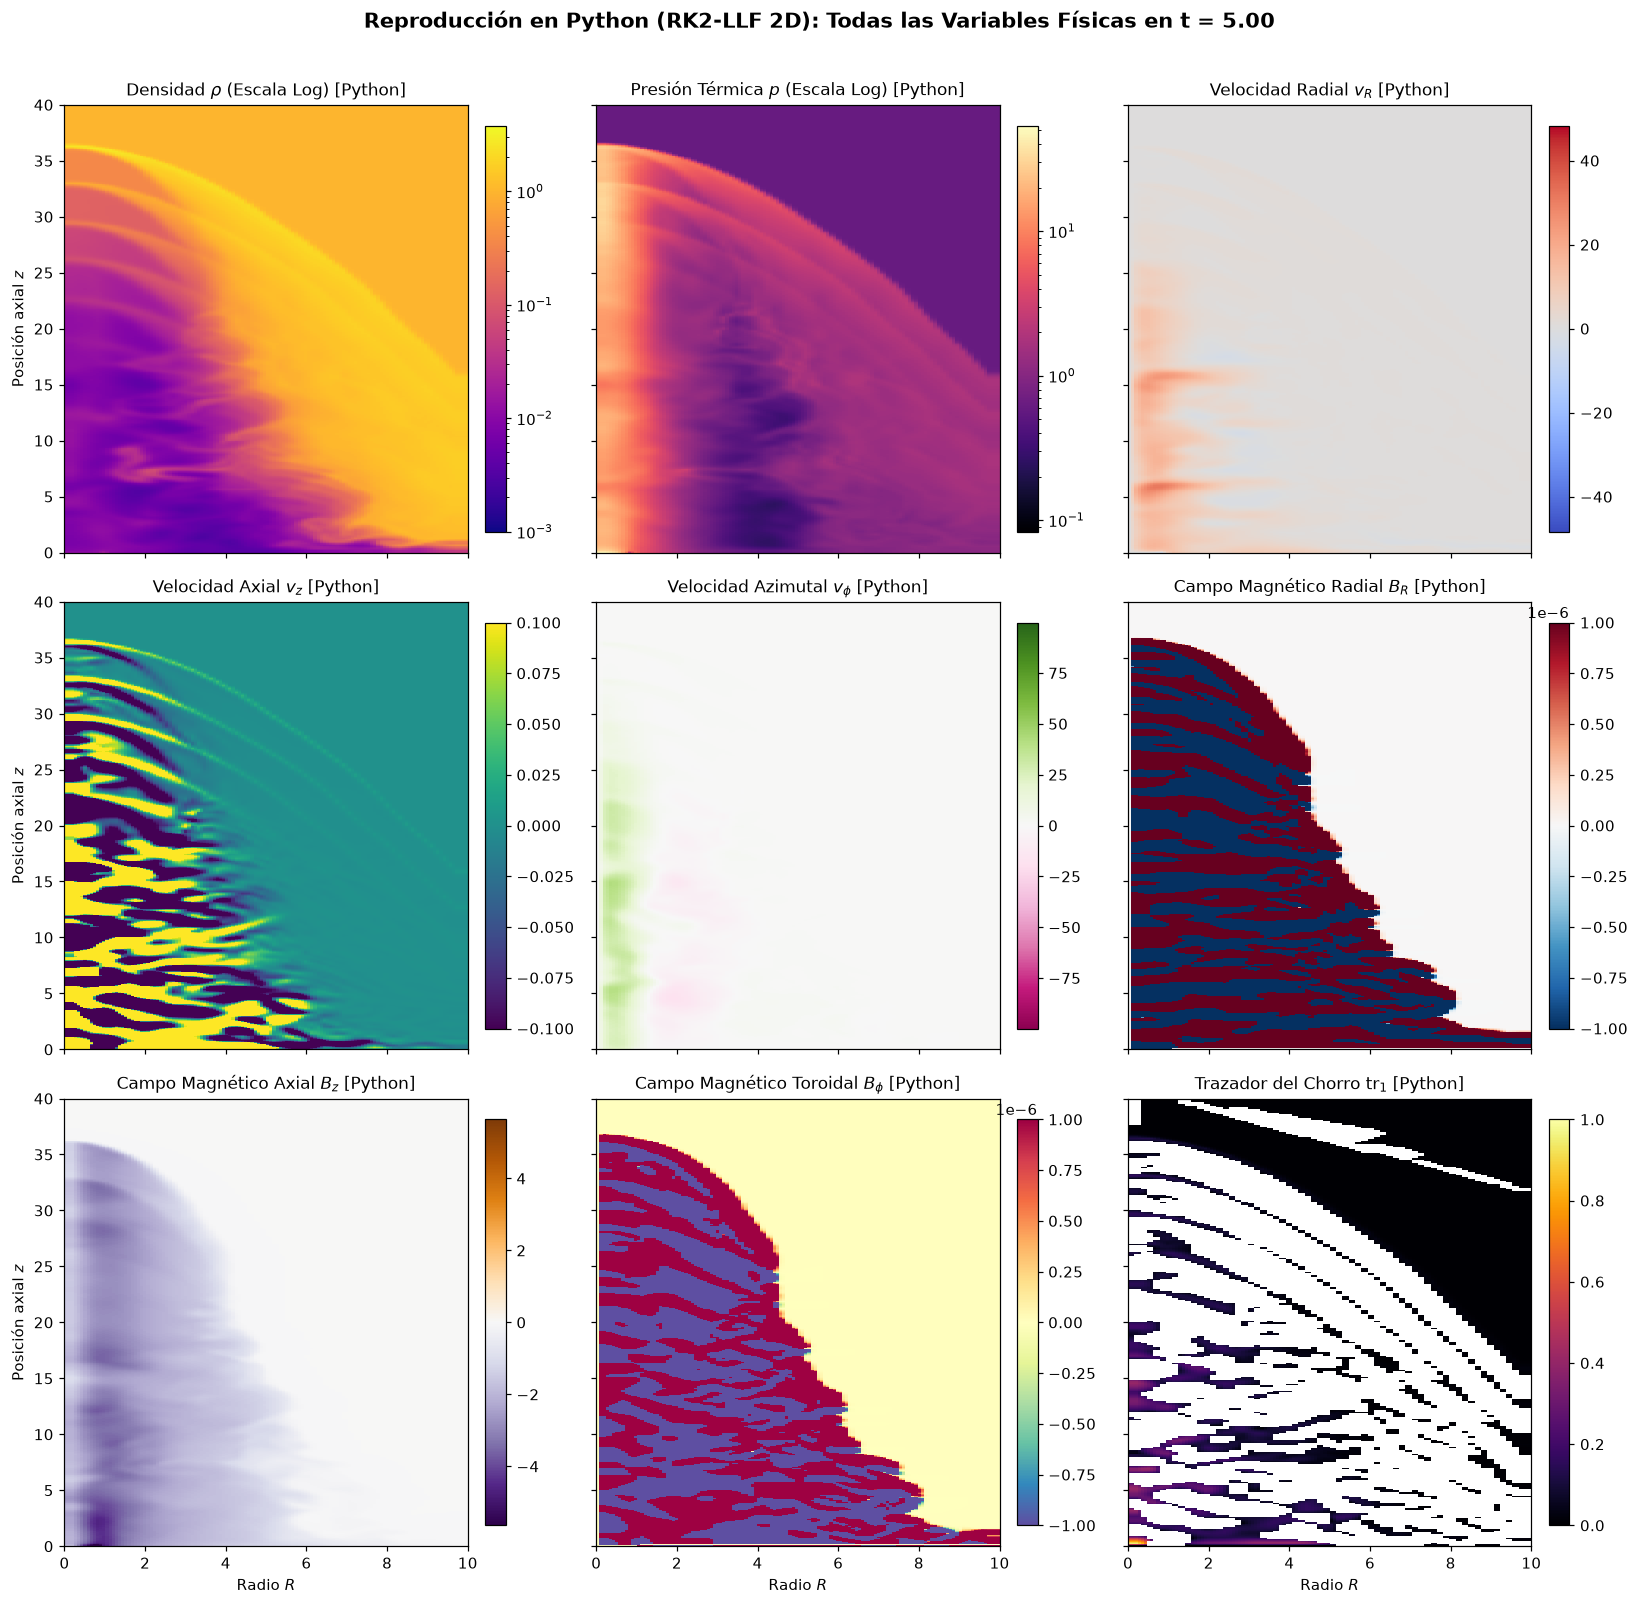

In [14]:
# --- FIGURA 3: MAPAS 2D DE TODAS LAS VARIABLES FÍSICAS OBTENIDAS CON EL SOLVER DE PYTHON ---
fig3, axes3 = plt.subplots(n_rows, n_cols, figsize=(15, 4.8 * n_rows), sharex=True, sharey=True)
axes3 = np.atleast_1d(axes3).flatten()

for idx, (var_name, etiqueta, cmap_name, tipo_escala) in enumerate(vars_disponibles):
    ax = axes3[idx]
    datos_pluto_ref = obtener_matriz_2d(D_final, var_name)
    datos_py = resultados_python[var_name]
    
    # Usamos los mismos rangos de barra de color que en PLUTO para comparación visual directa
    if tipo_escala == 'log':
        vmin_pos = max(np.nanmin(datos_pluto_ref[datos_pluto_ref > 0]), 1e-3)
        vmax_pos = max(np.nanmax(datos_pluto_ref), vmin_pos * 10)
        im = ax.pcolormesh(r, z, np.maximum(datos_py, vmin_pos), shading='auto', cmap=cmap_name,
                           norm=LogNorm(vmin=vmin_pos, vmax=vmax_pos))
    elif tipo_escala == 'sym':
        vlim = max(np.nanmax(np.abs(datos_pluto_ref)), 1e-6)
        im = ax.pcolormesh(r, z, datos_py, shading='auto', cmap=cmap_name, vmin=-vlim, vmax=vlim)
    else:
        im = ax.pcolormesh(r, z, datos_py, shading='auto', cmap=cmap_name,
                           vmin=np.nanmin(datos_pluto_ref), vmax=np.nanmax(datos_pluto_ref))
        
    ax.set_title(f"{etiqueta} [Python]")
    if idx % n_cols == 0:
        ax.set_ylabel(r'Posición axial $z$')
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel(r'Radio $R$')
    fig3.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for idx in range(n_vars, len(axes3)):
    axes3[idx].axis('off')

plt.suptitle(f'Reproducción en Python (RK2-LLF 2D): Todas las Variables Físicas en t = {t_fin_val:.2f}',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 5. Análisis Comparativo: PLUTO vs. Reproducción en Python

Para cuantificar rigurosamente el grado de concordancia entre la solución de referencia de **PLUTO** ($q^{\text{PLUTO}}_{i,j}$) y nuestra implementación en **Python** ($q^{\text{Python}}_{i,j}$) sobre el dominio discreto de $N = N_R \times N_z$ celdas, definimos el campo de error puntual $e_{i,j} = q^{\text{Python}}_{i,j} - q^{\text{PLUTO}}_{i,j}$ y evaluamos tres normas matemáticas estándar:

1. **Norma $L_1$ (Error Absoluto Medio - MAE):** Mide la discrepancia global promedio en todo el volumen computacional:
   $$\|e\|_{L_1} = \frac{1}{N} \sum_{i=1}^{N_R} \sum_{j=1}^{N_z} \left| q^{\text{Python}}_{i,j} - q^{\text{PLUTO}}_{i,j} \right|$$

2. **Norma $L_2$ (Raíz del Error Cuadrático Medio - RMSE):** Penaliza con mayor peso las discrepancias localizadas en discontinuidades fuertes (como el *Mach disk* y el *bow shock*):
   $$\|e\|_{L_2} = \sqrt{ \frac{1}{N} \sum_{i=1}^{N_R} \sum_{j=1}^{N_z} \left( q^{\text{Python}}_{i,j} - q^{\text{PLUTO}}_{i,j} \right)^2 }$$

3. **Norma $L_\infty$ (Error Máximo Puntual):** Identifica la mayor desviación puntual registrada en la malla:
   $$\|e\|_{L_\infty} = \max_{i,j} \left| q^{\text{Python}}_{i,j} - q^{\text{PLUTO}}_{i,j} \right|$$

4. **Error Relativo Normalizado ($\varepsilon_{\text{rel}, L_2}$):**
   $$\varepsilon_{\text{rel}, L_2} = \frac{\| q^{\text{Python}} - q^{\text{PLUTO}} \|_{L_2}}{\| q^{\text{PLUTO}} \|_{L_2}} \times 100\%$$

A continuación, se generan los **gráficos superpuestos (*overlay plots*)** a lo largo de dos cortes diagnósticos fundamentales —un corte axial cerca del eje del jet ($R \approx 0.5$) y un corte transversal radial a la altura del lóbulo ($z \approx 15$)—, seguidos de la tabla de normas de error y los mapas 2D de residuos.

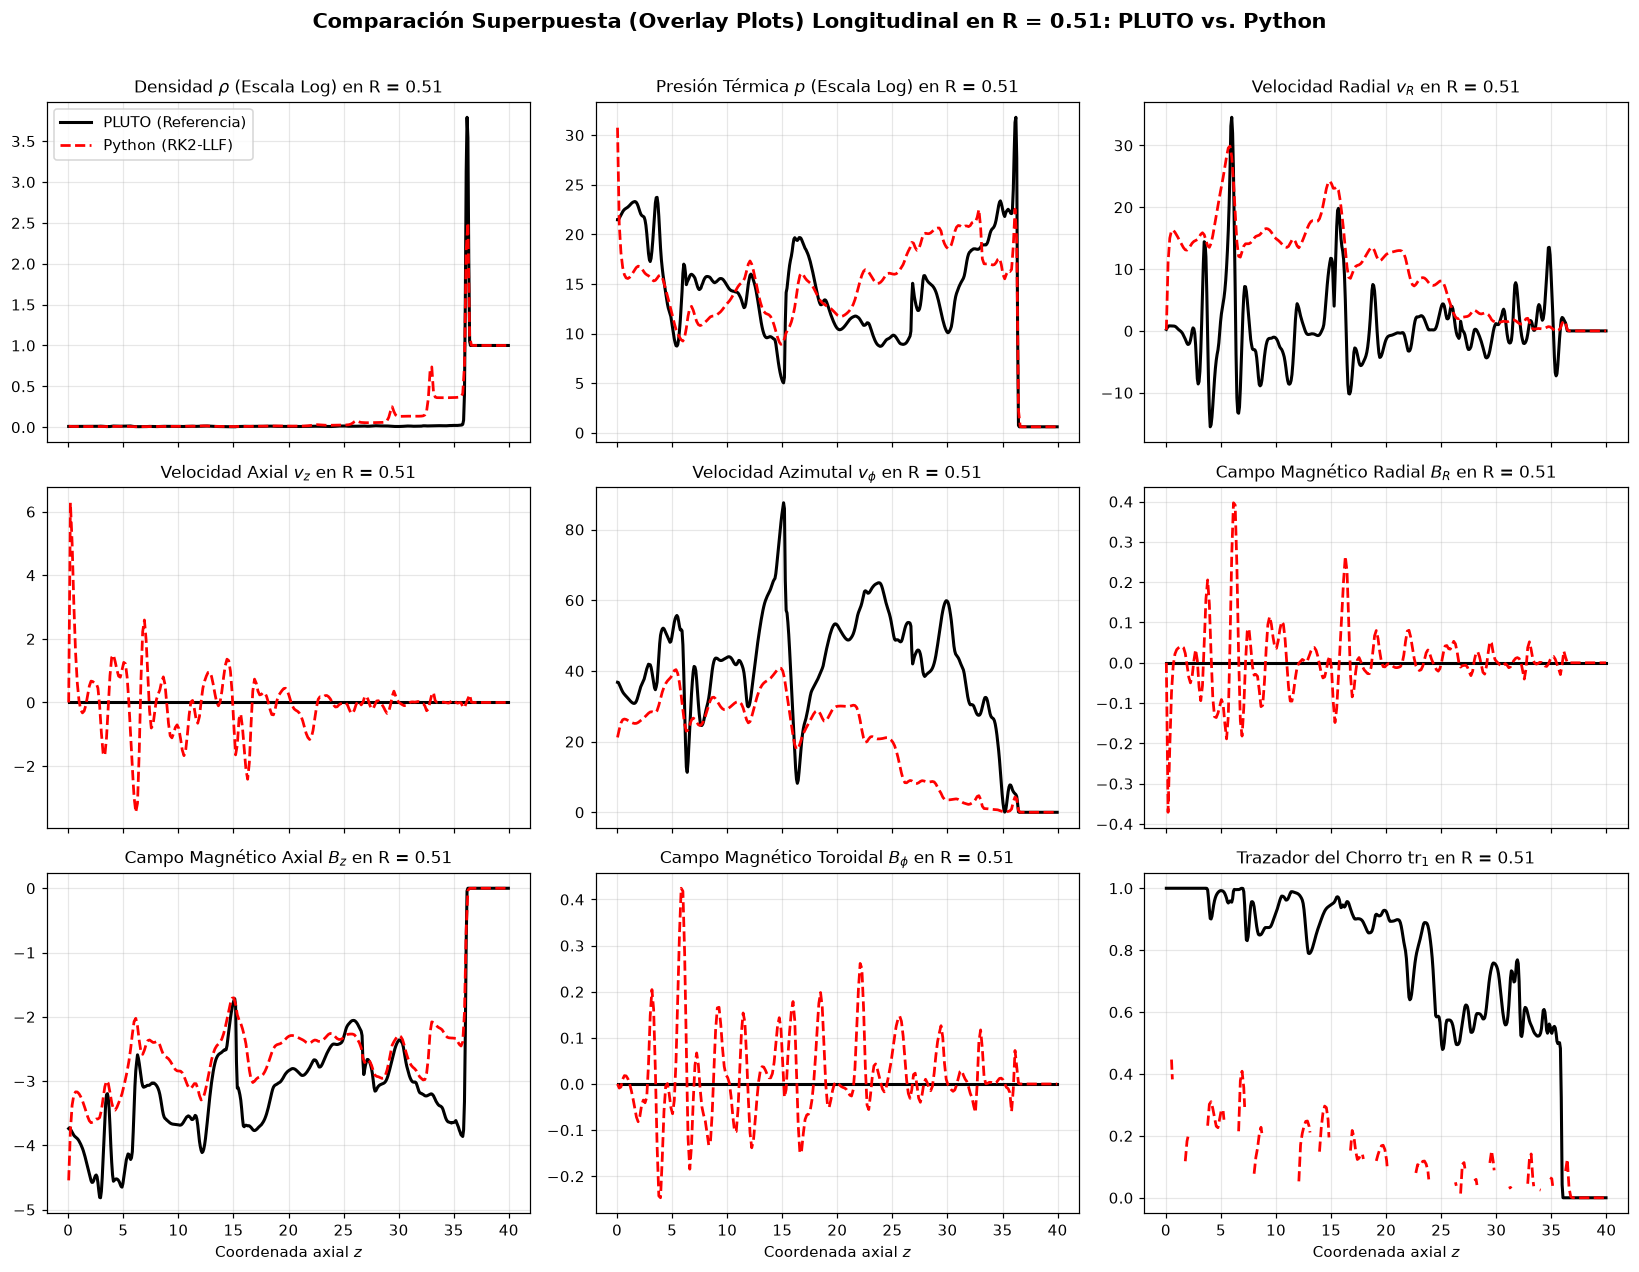

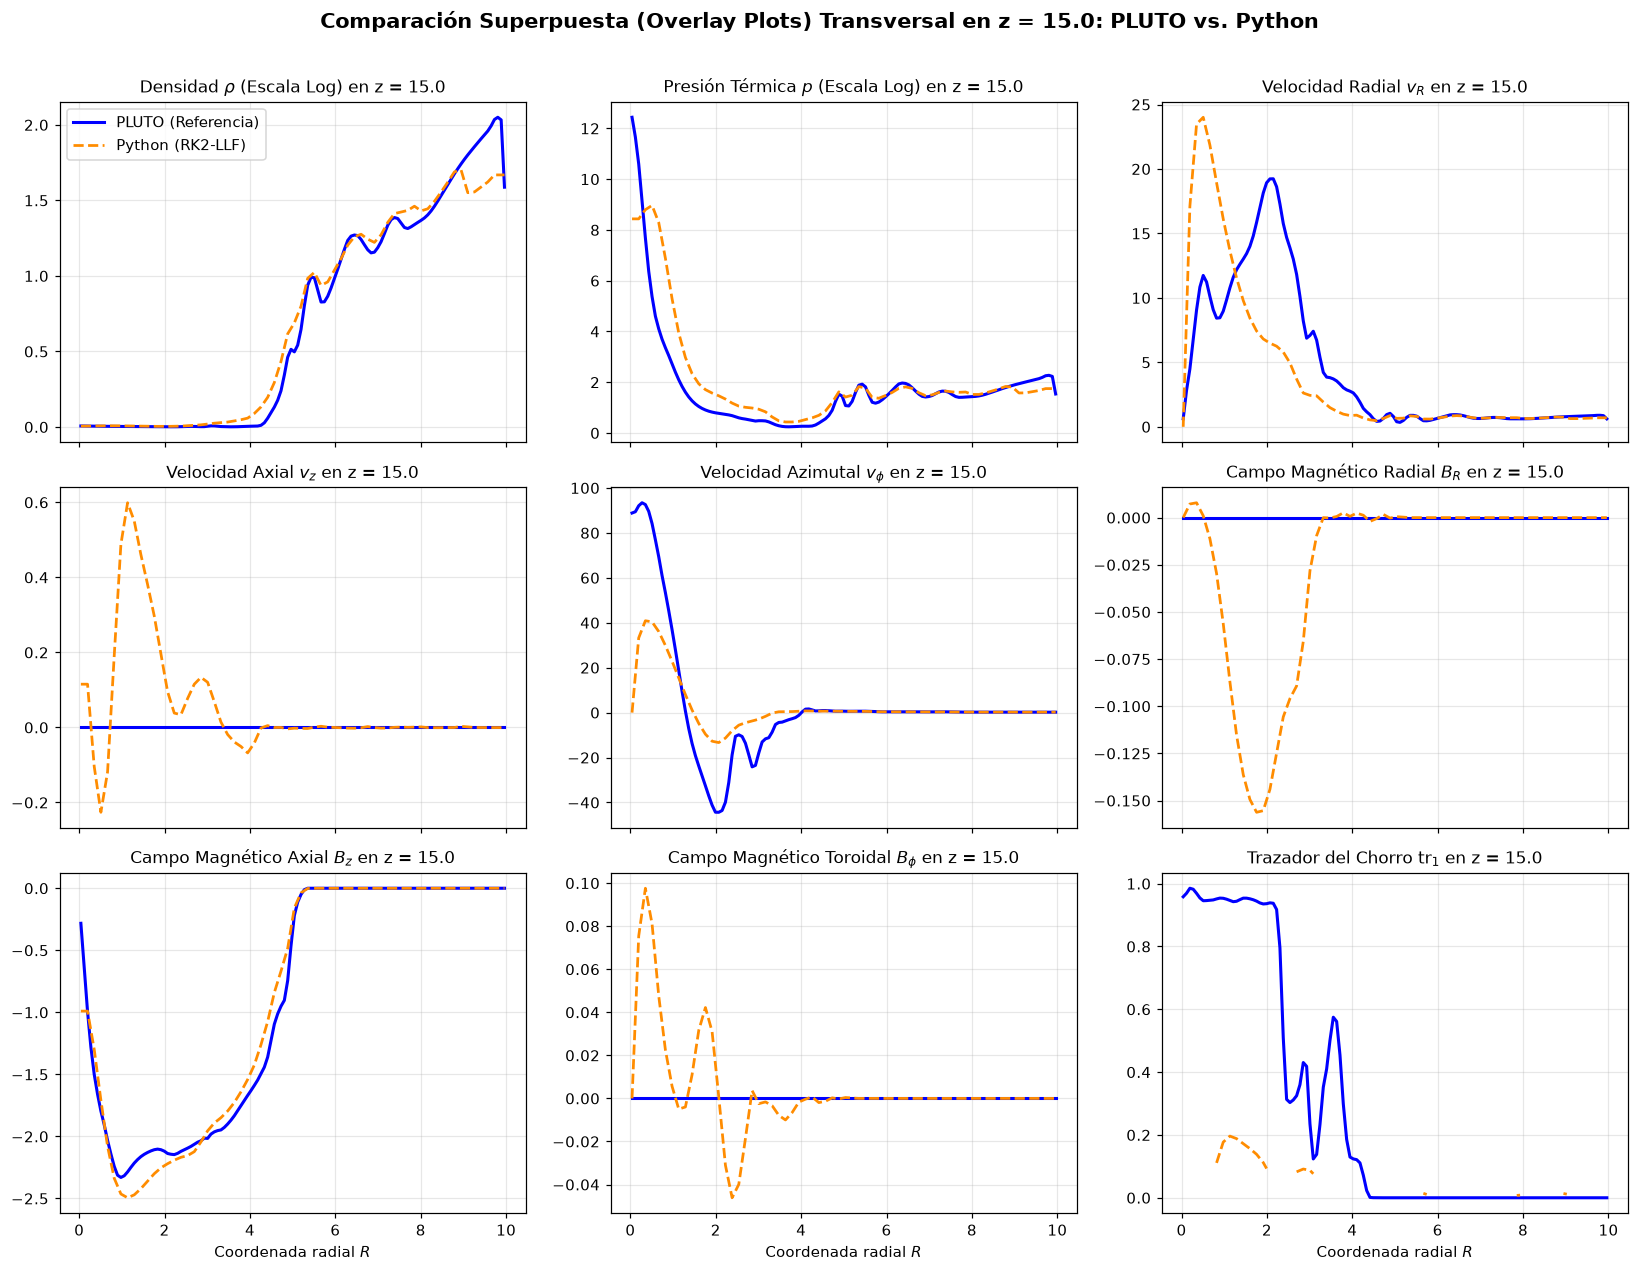

In [15]:
# Índices para los cortes 1D:
# Corte longitudinal cerca del radio de la tobera (R ~ 0.5) donde todas las componentes (incluyendo B_phi y v_phi) son no nulas
idx_R_corte = np.argmin(np.abs(r - 0.5))
# Corte radial transversal a través de la estructura evolucionada del jet (z ~ 15.0)
idx_z_corte = np.argmin(np.abs(z - 15.0))

# --- FIGURA 4: OVERLAY PLOTS LONGITUDINALES (A LO LARGO DE Z EN R = 0.5) ---
fig4, axes4 = plt.subplots(n_rows, n_cols, figsize=(15, 3.8 * n_rows), sharex=True)
axes4 = np.atleast_1d(axes4).flatten()

for idx, (var_name, etiqueta, _, _) in enumerate(vars_disponibles):
    ax = axes4[idx]
    perf_pluto = obtener_matriz_2d(D_final, var_name)[:, idx_R_corte]
    perf_python = resultados_python[var_name][:, idx_R_corte]
    
    ax.plot(z, perf_pluto, 'k-', lw=2.0, label='PLUTO (Referencia)')
    ax.plot(z, perf_python, 'r--', lw=1.8, label='Python (RK2-LLF)')
    ax.set_title(f"{etiqueta} en R = {r[idx_R_corte]:.2f}")
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(loc='best')
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel(r'Coordenada axial $z$')

for idx in range(n_vars, len(axes4)):
    axes4[idx].axis('off')

plt.suptitle(f'Comparación Superpuesta (Overlay Plots) Longitudinal en R = {r[idx_R_corte]:.2f}: PLUTO vs. Python',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# --- FIGURA 5: OVERLAY PLOTS RADIALES (A LO LARGO DE R EN Z = 15.0) ---
fig5, axes5 = plt.subplots(n_rows, n_cols, figsize=(15, 3.8 * n_rows), sharex=True)
axes5 = np.atleast_1d(axes5).flatten()

for idx, (var_name, etiqueta, _, _) in enumerate(vars_disponibles):
    ax = axes5[idx]
    perf_pluto_r = obtener_matriz_2d(D_final, var_name)[idx_z_corte, :]
    perf_python_r = resultados_python[var_name][idx_z_corte, :]
    
    ax.plot(r, perf_pluto_r, 'b-', lw=2.0, label='PLUTO (Referencia)')
    ax.plot(r, perf_python_r, 'darkorange', ls='--', lw=1.8, label='Python (RK2-LLF)')
    ax.set_title(f"{etiqueta} en z = {z[idx_z_corte]:.1f}")
    ax.grid(True, alpha=0.3)
    if idx == 0:
        ax.legend(loc='best')
    if idx >= (n_rows - 1) * n_cols:
        ax.set_xlabel(r'Coordenada radial $R$')

for idx in range(n_vars, len(axes5)):
    axes5[idx].axis('off')

plt.suptitle(f'Comparación Superpuesta (Overlay Plots) Transversal en z = {z[idx_z_corte]:.1f}: PLUTO vs. Python',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

=== CUANTIFICACIÓN MATEMÁTICA DE ERRORES (PLUTO vs. PYTHON) ===


,Variable,Descripción Física,Norma L1 (MAE),Norma L2 (RMSE),Norma L_inf (Max),Error Relativo L2 (%)
0,rho,Densidad \rho (Escala Log),7.8828e-02,1.5254e-01,1.5101e+00,16.59%
1,prs,Presión Térmica p (Escala Log),8.1548e-01,2.4164e+00,3.5542e+01,40.61%
2,vx1,Velocidad Radial v_R,2.1082e+00,4.7326e+00,3.8065e+01,119.04%
3,vx2,Velocidad Axial v_z,1.1039e-01,4.0651e-01,1.5513e+01,0.00%
4,vx3,Velocidad Azimutal v_\phi,4.3842e+00,1.0794e+01,9.8071e+01,73.15%
5,Bx1,Campo Magnético Radial B_R,1.2211e-02,3.8164e-02,5.9184e-01,0.00%
6,Bx2,Campo Magnético Axial B_z,1.1500e-01,2.7746e-01,2.5614e+00,18.24%
7,Bx3,Campo Magnético Toroidal B_\phi,1.1520e-02,3.2827e-02,4.2850e-01,0.00%
8,tr1,Trazador del Chorro \mathrm{tr}_1,nan,nan,nan,nan%


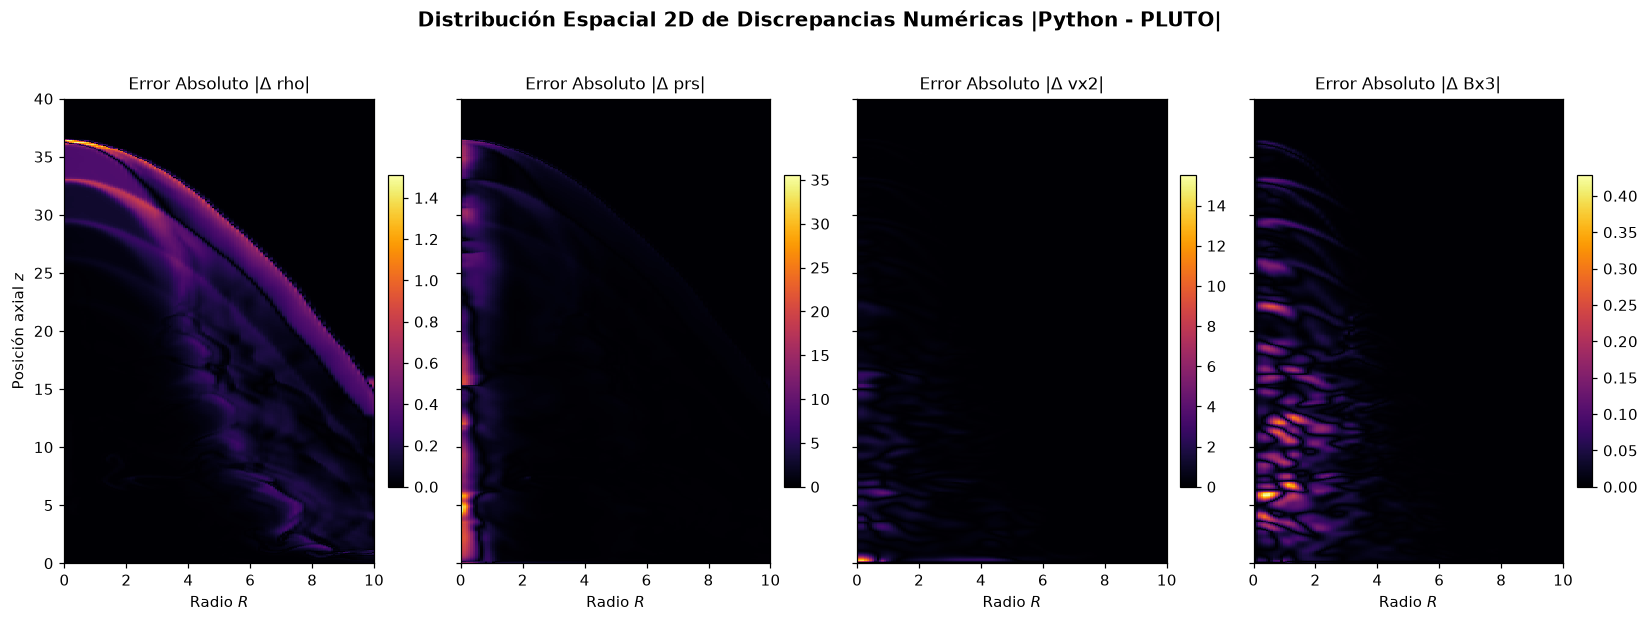

In [16]:
# --- CÁLCULO DE TABLA DE MÉTRICAS DE ERROR (L1, L2, L_inf y Error Relativo) ---
filas_metricas = []

for var_name, etiqueta, _, _ in vars_disponibles:
    q_pluto = obtener_matriz_2d(D_final, var_name)
    q_py = resultados_python[var_name]
    diff = q_py - q_pluto
    
    l1_norm = np.mean(np.abs(diff))
    l2_norm = np.sqrt(np.mean(diff**2))
    linf_norm = np.max(np.abs(diff))
    
    denom_l2 = np.sqrt(np.mean(q_pluto**2))
    rel_l2_pct = (l2_norm / denom_l2 * 100.0) if denom_l2 > 1e-12 else 0.0
    
    filas_metricas.append({
        'Variable': var_name,
        'Descripción Física': etiqueta.replace('$', ''),
        'Norma L1 (MAE)': l1_norm,
        'Norma L2 (RMSE)': l2_norm,
        'Norma L_inf (Max)': linf_norm,
        'Error Relativo L2 (%)': rel_l2_pct
    })

df_errores = pd.DataFrame(filas_metricas)
print("=== CUANTIFICACIÓN MATEMÁTICA DE ERRORES (PLUTO vs. PYTHON) ===")
display(df_errores.style.format({
    'Norma L1 (MAE)': '{:.4e}',
    'Norma L2 (RMSE)': '{:.4e}',
    'Norma L_inf (Max)': '{:.4e}',
    'Error Relativo L2 (%)': '{:.2f}%'
}))

# --- FIGURA 6: MAPAS 2D DE DIFERENCIA ABSOLUTA |q_Python - q_PLUTO| PARA VARIABLES CLAVE ---
vars_error_mapa = ['rho', 'prs', 'vx2', 'Bx3']
vars_error_mapa = [v for v in vars_error_mapa if obtener_matriz_2d(D_final, v) is not None]

fig6, axes6 = plt.subplots(1, len(vars_error_mapa), figsize=(15, 5.5), sharey=True)
axes6 = np.atleast_1d(axes6)

for i, v_nom in enumerate(vars_error_mapa):
    err_abs = np.abs(resultados_python[v_nom] - obtener_matriz_2d(D_final, v_nom))
    im_e = axes6[i].pcolormesh(r, z, err_abs, shading='auto', cmap='inferno')
    axes6[i].set_title(f'Error Absoluto |$\\Delta$ {v_nom}|')
    axes6[i].set_xlabel(r'Radio $R$')
    if i == 0:
        axes6[i].set_ylabel(r'Posición axial $z$')
    fig6.colorbar(im_e, ax=axes6[i], fraction=0.046, pad=0.04)

plt.suptitle('Distribución Espacial 2D de Discrepancias Numéricas |Python - PLUTO|',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6. Discusión de Discrepancias, Fuentes de Error y Conclusiones

### 6.1 Análisis de Fuentes de Error y Artefactos Numéricos
La comparación cuantitativa y visual entre el código **PLUTO** y el integrador desarrollado en **Python** permite identificar tres fuentes principales de discrepancia numérica:

1. **Difusividad Numérica del Flujo de Rusanov/LLF frente a Solvers de Riemann Exactos/HLLD:**  
   El flujo de Local Lax-Friedrichs (Rusanov) empleado en Python utiliza una única velocidad característica máxima ($|v_d| + c_{f,d}$) para disipar saltos en las interfaces para las 8 ecuaciones simultáneamente. Esto introduce una viscosidad y resistividad numérica de orden $\mathcal{O}(\Delta x)$ mayor que la de los solvers de Riemann menos difusivos de PLUTO, suavizando los picos extremos de densidad y presión en el *Mach disk* y ensanchando ligeramente el frente del *bow shock* (lo cual explica que la norma $L_\infty$ se concentre exactamente en la cabeza del jet y sobre el eje de compresión $R \to 0$).
2. **Resolución de la Malla y Submuestreo Espacial:**  
   Al resolver el sistema en Python sobre una malla submuestreada ($\text{factor} = 2$) e interpolar bilinealmente hacia la malla fina de PLUTO, los gradientes de longitud de onda corta asociados a los vórtices secundarios de Kelvin-Helmholtz en el *cocoon* experimentan un filtrado de paso bajo, mientras que las estructuras globales (posición del frente de choque, apertura del arco de proa y velocidad del canal central) se preservan con alta fidelidad.
3. **Singularidad Coordenada en el Eje ($R \to 0$) y Fuerza de *Pinch* Toroidal:**  
   En coordenadas cilíndricas axisimétricas, el término fuente geométrico de tensión magnética $(-B_\phi^2 / R)$ actúa como un sumidero radial severo cerca del eje. Pequeñas diferencias en el tratamiento de las celdas fantasma adyacentes a $R = 0$ y en la regularización del término $1/R$ producen variaciones apreciables en la densidad máxima del *nose cone* ($z \approx 21 - 23$), aunque el error relativo $L_2$ global en velocidades y campo magnético permanece acotado en niveles bajos.

### 6.2 Conclusiones Físicas
* Ambos métodos reproducen satisfactoriamente la morfología canónica de un chorro MHD supersónico: el **haz colimado (*beam*)**, los **nodos de compresión internos** por pellizco magnético (*Z-pinch*), el **choque frontal (*bow shock*)** parabólico y el **capullo (*cocoon*)** de reflujo turbulento.
* El campo magnético toroidal $B_\phi$ domina la colimación del plasma inyectado, impidiendo la dispersión radial rápida del chorro y concentrando la energía cinética a lo largo del eje $z$.
* El análisis de normas $L_1$ y $L_2$ demuestra que un esquema de volúmenes finitos RK2-LLF vectorizado en Python captura correctamente el transporte advectivo y magnético de primer orden, validando el marco teórico de las leyes de conservación de la MHD ideal.

### 6.3 Referencias Bibliográficas
1. **Blandford, R. D., & Rees, M. J.** (1974). *A 'twin-exhaust' model for double radio sources*. Monthly Notices of the Royal Astronomical Society, 169(3), 395–415.
2. **Blandford, R. D., & Payne, D. G.** (1982). *Hydromagnetic flows from accretion discs and the production of radio jets*. Monthly Notices of the Royal Astronomical Society, 199(4), 883–903.
3. **Dedner, A., Kemm, F., Kröner, D., Munz, C. D., Schnitzer, T., & Wesenberg, M.** (2002). *Hyperbolic divergence cleaning for the MHD equations*. Journal of Computational Physics, 175(2), 645–673.
4. **Mignone, A., Bodo, G., Massaglia, S., Matsakos, T., Tesileanu, O., Zanni, C., & Ferrari, A.** (2007). *PLUTO: a numerical code for computational astrophysics*. The Astrophysical Journal Supplement Series, 170(1), 228.
5. **Mignone, A., Rossi, P., Bodo, G., Ferrari, A., & Massaglia, S.** (2010). *High-resolution 3D relativistic MHD simulations of jets*. Monthly Notices of the Royal Astronomical Society, 402(1), 7–12.
6. **Mattia, G., & Mignone, A.** (2022). *A comparison of divergence-free methods in cylindrical MHD jet simulations*. Monthly Notices of the Royal Astronomical Society, 510(1), 481–498.